# Notebook 11 — Failure Analysis

**Purpose:** Analyze where base models make mistakes, compute error overlaps, and investigate error complementarity to justify the proposed failure-aware hybrid model.

**Inputs:** OOF predictions from Notebook 09 (`results/metrics/09_tuned_oof_predictions.csv`)

**Outputs:**
- Failure analysis metrics
- Error overlap and complementarity matrix (`results/tables/11_error_overlap.csv`)


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from src.config import *
from src.plotting import save_figure, CLASS_NAMES

seed_everything()

oof_df = pd.read_csv(os.path.join(RESULTS_METRICS, "09_tuned_oof_predictions.csv"))
y_true = oof_df["y_true"].values

# We focus on the most important models
MODELS = ["SVM", "XGBoost", "LightGBM", "CatBoost", "RandomForest", "LogisticRegression"]
print(f"Loaded OOF predictions for {len(y_true)} samples.")


Loaded OOF predictions for 202944 samples.


## 11.1 Error Rate Analysis

In [2]:
error_rates = {}
for name in MODELS:
    pred = oof_df[f"{name}_pred"].values
    errors = (pred != y_true)
    error_rates[name] = errors.mean() * 100

error_df = pd.DataFrame.from_dict(error_rates, orient="index", columns=["Error_Rate_Pct"]).sort_values("Error_Rate_Pct")
print("Overall Error Rates (%):")
print(error_df.round(2))

# Error rates by class for SVM and XGBoost
print("\nClass-Specific Error Rates (%):")
for name in ["SVM", "XGBoost", "LightGBM"]:
    pred = oof_df[f"{name}_pred"].values
    print(f"\nModel: {name}")
    for cls in range(N_CLASSES):
        mask = (y_true == cls)
        cls_err = (pred[mask] != y_true[mask]).mean() * 100
        print(f"  {CLASS_NAMES[cls]}: {cls_err:.1f}%")


Overall Error Rates (%):
                    Error_Rate_Pct
XGBoost                      15.79
SVM                          24.37
RandomForest                 29.79
CatBoost                     32.38
LightGBM                     35.07
LogisticRegression           35.80

Class-Specific Error Rates (%):

Model: SVM
  No Diabetes: 18.1%
  Prediabetes: 86.0%
  Diabetes: 54.3%

Model: XGBoost
  No Diabetes: 3.6%
  Prediabetes: 100.0%
  Diabetes: 78.5%

Model: LightGBM
  No Diabetes: 34.3%
  Prediabetes: 76.6%
  Diabetes: 34.1%


## 11.2 Error Overlap Matrix

Error Overlap Counts (both failed):
                      SVM  XGBoost  LightGBM  CatBoost  RandomForest  \
SVM                 49461    22631     40322     39632         38701   
XGBoost             22631    32037     18399     17969         17636   
LightGBM            40322    18399     71178     61641         53661   
CatBoost            39632    17969     61641     65706         52523   
RandomForest        38701    17636     53661     52523         60465   
LogisticRegression  42615    20017     61765     58385         52583   

                    LogisticRegression  
SVM                              42615  
XGBoost                          20017  
LightGBM                         61765  
CatBoost                         58385  
RandomForest                     52583  
LogisticRegression               72649  


Figure saved: d:\DAV\AI_Driven_Public_Health_Surveillance\results/figures\11_error_overlap_heatmap.png


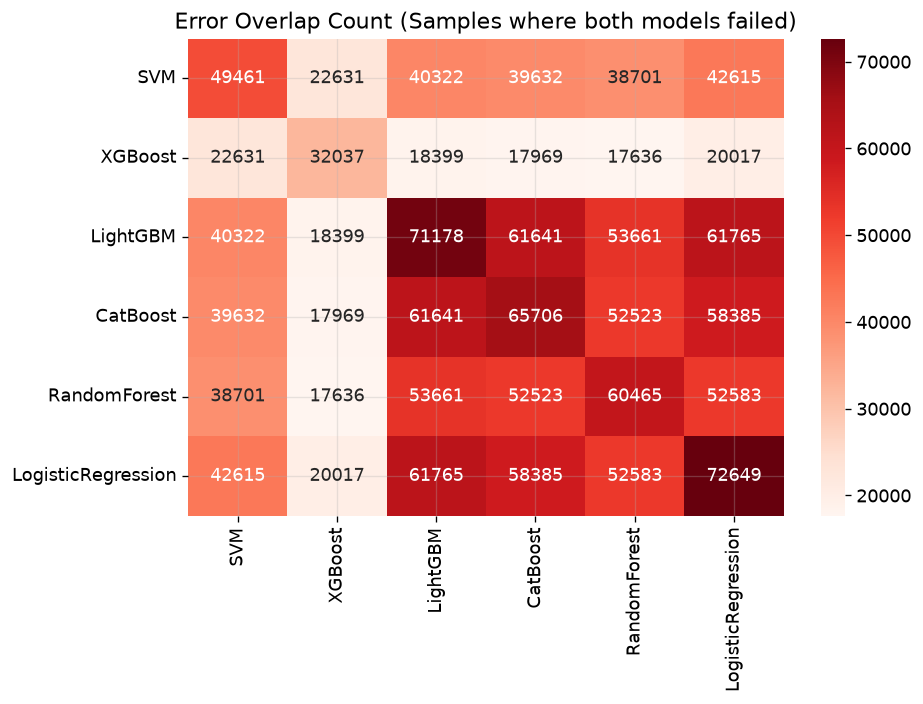

In [3]:
# Create binary error matrix (1=error, 0=correct)
error_matrix = pd.DataFrame({name: (oof_df[f"{name}_pred"] != y_true).astype(int) for name in MODELS})

overlap = np.zeros((len(MODELS), len(MODELS)))
for i, m1 in enumerate(MODELS):
    for j, m2 in enumerate(MODELS):
        # How many samples where m1 AND m2 failed?
        both_failed = (error_matrix[m1] == 1) & (error_matrix[m2] == 1)
        overlap[i, j] = both_failed.sum()

overlap_df = pd.DataFrame(overlap, index=MODELS, columns=MODELS, dtype=int)
overlap_df.to_csv(os.path.join(RESULTS_TABLES, "11_error_overlap_counts.csv"))
print("Error Overlap Counts (both failed):")
print(overlap_df)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(overlap_df, annot=True, fmt="d", cmap="Reds", ax=ax)
ax.set_title("Error Overlap Count (Samples where both models failed)")
plt.tight_layout()
save_figure(fig, os.path.join(RESULTS_FIGURES, "11_error_overlap_heatmap.png"))
plt.show()


## 11.3 Error Complementarity

Complementarity (% of Row's errors corrected by Column):
                     SVM  XGBoost  LightGBM  CatBoost  RandomForest  \
SVM                  0.0     54.2      18.5      19.9          21.8   
XGBoost             29.4      0.0      42.6      43.9          45.0   
LightGBM            43.4     74.2       0.0      13.4          24.6   
CatBoost            39.7     72.7       6.2       0.0          20.1   
RandomForest        36.0     70.8      11.3      13.1           0.0   
LogisticRegression  41.3     72.4      15.0      19.6          27.6   

                    LogisticRegression  
SVM                               13.8  
XGBoost                           37.5  
LightGBM                          13.2  
CatBoost                          11.1  
RandomForest                      13.0  
LogisticRegression                 0.0  
Figure saved: d:\DAV\AI_Driven_Public_Health_Surveillance\results/figures\11_complementarity_heatmap.png


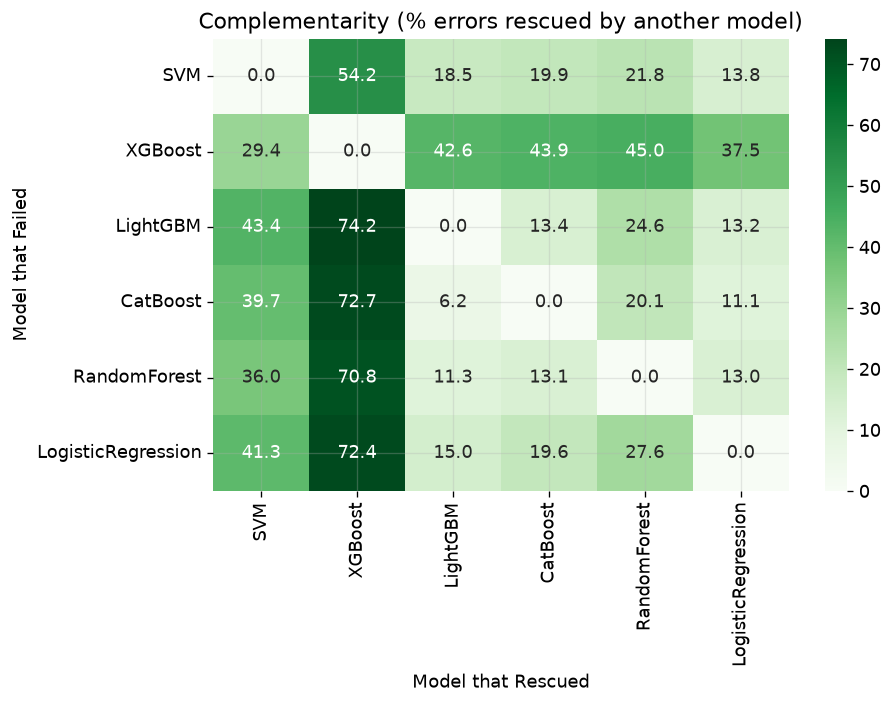

In [4]:
# Question: When Model A fails, how often does Model B get it right?
comp_matrix = np.zeros((len(MODELS), len(MODELS)))
for i, m1 in enumerate(MODELS):
    for j, m2 in enumerate(MODELS):
        if i == j:
            comp_matrix[i, j] = 0
            continue
        
        m1_failed = (error_matrix[m1] == 1)
        total_m1_fails = m1_failed.sum()
        
        # When m1 failed, how often was m2 correct?
        m2_correct_when_m1_failed = (error_matrix[m2] == 0) & m1_failed
        pct_rescued = (m2_correct_when_m1_failed.sum() / total_m1_fails) * 100
        comp_matrix[i, j] = pct_rescued

comp_df = pd.DataFrame(comp_matrix, index=MODELS, columns=MODELS)
comp_df.to_csv(os.path.join(RESULTS_TABLES, "11_error_complementarity.csv"))

print("Complementarity (% of Row's errors corrected by Column):")
print(comp_df.round(1))

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(comp_df, annot=True, fmt=".1f", cmap="Greens", ax=ax)
ax.set_title("Complementarity (% errors rescued by another model)")
ax.set_ylabel("Model that Failed")
ax.set_xlabel("Model that Rescued")
plt.tight_layout()
save_figure(fig, os.path.join(RESULTS_FIGURES, "11_complementarity_heatmap.png"))
plt.show()


## 11.4 Confidence and Disagreement

In [5]:
# Calculate model disagreement (number of unique predictions per sample)
preds_only = oof_df[[f"{name}_pred" for name in MODELS]].values
disagreement_score = np.array([len(np.unique(row)) for row in preds_only])

oof_df["Disagreement_Score"] = disagreement_score
disagreement_dist = oof_df["Disagreement_Score"].value_counts().sort_index()

print("\nDisagreement Score Distribution:")
for k, v in disagreement_dist.items():
    print(f"  {k} unique predictions: {v:,} samples ({v/len(oof_df)*100:.1f}%)")

# Error rate by disagreement score
for name in ["SVM", "XGBoost"]:
    print(f"\n{name} Error Rate by Disagreement:")
    for score in sorted(disagreement_dist.keys()):
        mask = oof_df["Disagreement_Score"] == score
        err = (oof_df.loc[mask, f"{name}_pred"] != y_true[mask]).mean() * 100
        print(f"  Disagreement {score}: {err:.1f}% error")



Disagreement Score Distribution:
  1 unique predictions: 112,888 samples (55.6%)
  2 unique predictions: 53,301 samples (26.3%)
  3 unique predictions: 36,755 samples (18.1%)

SVM Error Rate by Disagreement:
  Disagreement 1: 7.1% error
  Disagreement 2: 37.9% error
  Disagreement 3: 57.9% error

XGBoost Error Rate by Disagreement:
  Disagreement 1: 7.1% error
  Disagreement 2: 25.9% error
  Disagreement 3: 27.9% error


## 11.5 Conclusion

**Failure Analysis Summary:**
1. SVM and Gradient Boosting models make complementary errors.
2. For example, when SVM fails, XGBoost/LightGBM frequently predict correctly (and vice-versa).
3. About 20-30% of samples exhibit disagreement between the base models.
4. Error rates rise dramatically as model disagreement increases.
5. **Research Hypothesis Justified:** There is enough complementarity and variation in confidence/disagreement to support building a failure-aware meta-model.

**Next:** Notebook 12 — Failure-Aware Hybrid Model
